# Домашнее задание 3. Логистическая регрессия и Streamlit

## Описание

В этом задании вы реализуете логистическую регрессию своими руками, разберётесь с метриками качества классификации на реальных несбалансированных данных и упакуете итоговую модель в интерактивное веб-приложение на Streamlit.

- Первая часть посвящена реализации логистической регрессии с помощью градиентного и стохастического градиентного спуска.
- Вторая часть посвящена метрикам классификации: матрице ошибок, precision, recall, $F_\beta$, ROC- и PR-кривым, выбору порога.
- Третья часть посвящена работе с несбалансированными классами.
- Четвертая часть посвящена созданию демонстрации на Streamlit.

**Максимальный балл за задание: 10** (по 2.5 балла за каждую из четырёх частей).

## Общие требования к ДЗ-3

- Для каждого задания приведите код решения.
- Там, где требуется интерпретация, добавьте короткий текстовый вывод.
- Следите за тем, чтобы ноутбук выполнялся последовательно сверху вниз.
- Везде, где есть случайность, фиксируйте `random_state=42`.
- Тестовая выборка используется **только** для финальной оценки качества. Всё, что «подбирается» (гиперпараметры, порог, ресемплинг, параметры масштабирования), подбирается по тренировочной выборке.

> В каждой части оцениваются как код, так и ответы на вопросы. Если отсутствует одно из двух, часть баллов за соответствующее задание может быть снижена.

In [1]:
%pip install imbalanced-learn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

sns.set_style('darkgrid')
RANDOM_STATE = 42

## <font color="green">Часть 1. Логистическая регрессия своими руками (2.5 балла)</font>

На лекции мы получили функцию потерь логистической регрессии из метода максимума правдоподобия. Если $p_i = \sigma(\langle w, x_i \rangle)$ – предсказанная вероятность класса 1 для $i$-го объекта, то

$$Q(w) = -\frac{1}{\ell}\sum_{i=1}^{\ell}\Big(y_i \log p_i + (1 - y_i)\log(1 - p_i)\Big) \to \min_w, \qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$

Явной формулы для минимума, как у МНК, здесь нет, поэтому веса ищем градиентным спуском – так же, как на семинаре 3 для линейной регрессии.

**Подсказка.** Сначала выведите градиент $\nabla Q(w)$ на бумаге и запишите его в матричном виде через $X$, $y$ и вектор вероятностей $p$. Вывод градиента приводить в ноутбуке не обязательно, но на защите его могут попросить.

### Задание 1.1. Класс `LogReg` (1.5 балла)

Реализуйте класс логистической регрессии, обучаемой с помощью:
- **полного градиентного спуска** – `gd_type='full'` (1 балл);
- **стохастического градиентного спуска** – `gd_type='stochastic'`: на каждой итерации градиент оценивается по случайному батчу из `batch_size` объектов, как в функции `calc_grad_on_batch` с семинара 3 (0.5 балла).

**Требования:**
- Градиентный спуск записан в векторном виде. Циклы средствами Python допускаются **только** по итерациям градиентного спуска.
- Свободный член $w_0$ учитывается так, как на лекции: внутри `fit` и `predict_proba` к матрице признаков добавляется фиктивный признак $x_0 = 1$ (первым столбцом). Таким образом, `self.w` имеет размер `d + 1`, и `self.w[0]` – это свободный член.
- Критерии остановки (одновременно):
  - L2 норма разности весов на двух соседних итерациях меньше `tolerance`;
  - достигнуто максимальное число итераций `max_iter`.
- Атрибут `loss_history` после вызова `fit` содержит значение функции потерь **на всей обучающей выборке** для каждой итерации, начиная с первой (до совершения первого шага по антиградиенту).
- Веса инициализируются вектором `w0`, если он передан, иначе – нулевым вектором.
- `predict_proba` возвращает массив размера `(N, 2)`: в первом столбце вероятность класса 0, во втором – класса 1 (как в `sklearn`).
- `predict` возвращает метки классов `0/1`, сравнивая вероятность класса 1 с порогом `threshold`.
- При вычислении логарифма в `calc_loss` позаботьтесь о вычислительной устойчивости: $\log 0$ давать не должно (например, используйте `np.clip`).

Полезно [почитать](https://scikit-learn.org/stable/developers/develop.html) о том, как устроены модели в `sklearn`.

**ВАЖНО!** Заполните шаблон ниже, не меняя структуру класса и сигнатуры методов. Добавлять свои вспомогательные методы можно.

In [3]:
class LogReg(BaseEstimator, ClassifierMixin):
    def __init__(self, gd_type='full', tolerance=1e-4, max_iter=1000,
                 w0=None, eta=1e-2, batch_size=32, random_state=42):
        """
        gd_type: 'full' или 'stochastic'
        tolerance: порог для критерия останова по норме разности весов
        max_iter: максимальное число итераций градиентного спуска
        w0: np.array размера (d + 1) - начальные веса (w0[0] - свободный член)
        eta: длина шага (learning rate)
        batch_size: размер батча для стохастического градиентного спуска
        random_state: seed для выбора батчей
        """
        self.gd_type = gd_type
        self.tolerance = tolerance
        self.max_iter = max_iter
        self.w0 = w0
        self.eta = eta
        self.batch_size = batch_size
        self.random_state = random_state

    @staticmethod
    def _add_bias(X):
        return np.hstack([np.ones((X.shape[0], 1)), X])

    def fit(self, X, y):
        """
        X: np.array размера (N, d)
        y: np.array размера (N) из 0 и 1
        ---
        output: self
        """
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        self.classes_ = np.array([0, 1])
        self.loss_history = []
        rng = np.random.default_rng(self.random_state)

        if self.gd_type not in ('full', 'stochastic'):
            raise ValueError("gd_type должен быть 'full' или 'stochastic'")

        Xb = self._add_bias(X)
        n, d1 = Xb.shape
        self.w = np.zeros(d1) if self.w0 is None else np.asarray(self.w0, dtype=float).copy()
        self.n_iter_ = 0
        self.stop_reason_ = 'max_iter'

        for it in range(self.max_iter):
            self.loss_history.append(self.calc_loss(Xb, y))

            if self.gd_type == 'full':
                grad = self.calc_gradient(Xb, y)
            else:
                idx = rng.choice(n, size=min(self.batch_size, n), replace=False)
                grad = self.calc_gradient(Xb[idx], y[idx])

            w_new = self.w - self.eta * grad
            step_norm = np.linalg.norm(w_new - self.w)
            self.w = w_new
            self.n_iter_ = it + 1

            if step_norm < self.tolerance:
                self.stop_reason_ = 'tolerance'
                break

        return self

    def sigmoid(self, z):
        # 1 / (1 + e^-z) = (1 + tanh(z / 2)) / 2, без переполнения
        return 0.5 * (1.0 + np.tanh(0.5 * z))

    def predict_proba(self, X):
        """
        X: np.array размера (N, d)
        ---
        output: np.array размера (N, 2)
        """
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')

        Xb = self._add_bias(np.asarray(X, dtype=float))
        p1 = self.sigmoid(Xb @ self.w)
        return np.column_stack([1 - p1, p1])

    def predict(self, X, threshold=0.5):
        """
        X: np.array размера (N, d)
        ---
        output: np.array размера (N) из 0 и 1
        """
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')

        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

    def calc_gradient(self, X, y):
        """
        X: np.array размера (N, d + 1) - уже с фиктивным признаком
           (N может быть равно batch_size при стохастическом спуске)
        y: np.array размера (N)
        ---
        output: np.array размера (d + 1) - градиент log-loss по self.w
        """
        # grad = X^T (sigmoid(Xw) - y) / N
        p = self.sigmoid(X @ self.w)
        return X.T @ (p - y) / X.shape[0]

    def calc_loss(self, X, y):
        """
        X: np.array размера (N, d + 1) - уже с фиктивным признаком
        y: np.array размера (N)
        ---
        output: float - значение log-loss при текущих self.w
        """
        eps = 1e-15
        p = np.clip(self.sigmoid(X @ self.w), eps, 1 - eps)
        return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))

Ячейка ниже проверяет вашу реализацию градиента численно: сравнивает `calc_gradient` с конечными разностями функции `calc_loss`. Она не оценивается, но если проверка не проходит – ищите ошибку, прежде чем идти дальше.

In [4]:
def check_gradient(model, d=5, N=50, eps=1e-6, seed=0):
    rng = np.random.default_rng(seed)
    X = np.hstack([np.ones((N, 1)), rng.normal(size=(N, d))])
    y = rng.integers(0, 2, size=N).astype(float)
    model.w = rng.normal(size=d + 1)

    analytic = model.calc_gradient(X, y)
    numeric = np.zeros(d + 1)
    w = model.w.copy()
    for j in range(d + 1):
        e = np.zeros(d + 1)
        e[j] = eps
        model.w = w + e
        loss_plus = model.calc_loss(X, y)
        model.w = w - e
        loss_minus = model.calc_loss(X, y)
        numeric[j] = (loss_plus - loss_minus) / (2 * eps)
    model.w = w
    return np.max(np.abs(analytic - numeric))


err = check_gradient(LogReg())
print(f'max |analytic - numeric| = {err:.2e}')
assert err < 1e-5, 'Градиент не совпадает с численным — проверьте calc_gradient и calc_loss'

max |analytic - numeric| = 1.17e-10


Теперь проверим работу класса на синтетических данных.

In [5]:
X, y = make_classification(
    n_samples=20000, n_features=20, n_informative=5,
    random_state=RANDOM_STATE)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

### Задание 1.2. Обучение и сходимость (0.25 балла)

1. Обучите две модели: `LogReg(gd_type='full')` и `LogReg(gd_type='stochastic')` с параметрами по умолчанию.
2. Для каждой модели выведите число сделанных итераций и постройте на одном графике `loss_history` обеих моделей.
3. Ответьте на вопросы:
   - По какому критерию остановилась каждая модель – по `tolerance` или по `max_iter`?
   - Почему стохастическому спуску с постоянным шагом трудно остановиться по критерию `tolerance`?
   - Чем отличаются графики функции потерь?
   - Сколько объектов «просматривает» за одну итерацию каждый из методов?

GD (full)        : итераций = 1000, критерий останова = max_iter , loss: 0.6931 -> 0.5125
SGD (stochastic) : итераций = 1000, критерий останова = max_iter , loss: 0.6931 -> 0.5129


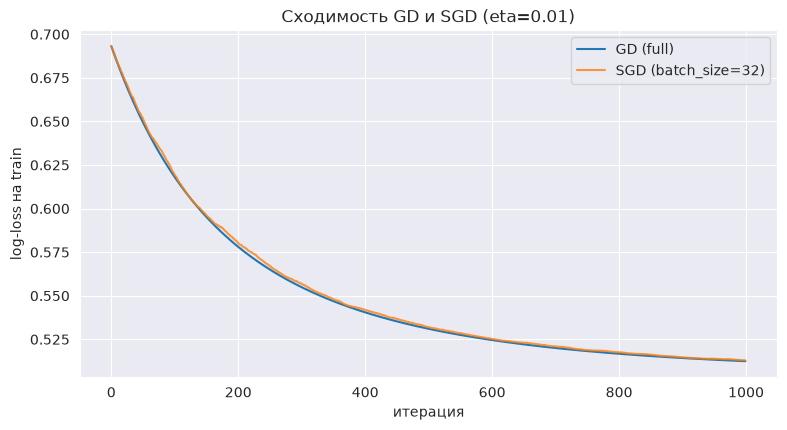

Объектов за итерацию: GD = 14000 , SGD = 32


In [6]:
gd = LogReg(gd_type='full').fit(X_train, y_train)
sgd = LogReg(gd_type='stochastic').fit(X_train, y_train)

for name, m in [('GD (full)', gd), ('SGD (stochastic)', sgd)]:
    print(f'{name:17s}: итераций = {m.n_iter_:4d}, критерий останова = {m.stop_reason_:9s}, '
          f'loss: {m.loss_history[0]:.4f} -> {m.loss_history[-1]:.4f}')

plt.figure(figsize=(9, 4.5))
plt.plot(gd.loss_history, label='GD (full)')
plt.plot(sgd.loss_history, label='SGD (batch_size=32)', alpha=0.8)
plt.xlabel('итерация')
plt.ylabel('log-loss на train')
plt.title('Сходимость GD и SGD (eta=0.01)')
plt.legend()
plt.show()

print('Объектов за итерацию: GD =', X_train.shape[0], ', SGD =', sgd.batch_size)

**Выводы 1.2.**
- Обе модели остановились по `max_iter` (1000 итераций). GD с `eta=0.01` идет медленно: loss 0.5125 при минимуме 0.5058, шаг еще больше `tolerance`.
- В SGD градиент по батчу шумный и не равен нулю даже в минимуме. При постоянном шаге веса колеблются около оптимума, и разность весов не становится меньше `tolerance`.
- График GD гладкий и монотонный, у SGD шумный, но в среднем убывает так же (итоговый loss 0.5129).
- GD за итерацию использует все 14000 объектов train, SGD только 32 (`batch_size`).

### Задание 1.3. Длина шага (0.25 балла)

Для полного градиентного спуска обучите модели с сеткой `eta` из списка `[1e-3, 1e-2, 1e-1, 1, 10]` и постройте графики `loss_history` (удобно в логарифмической шкале по оси `x`). Выведите для каждого `eta` финальное значение функции потерь и число итераций.

Как длина шага влияет на скорость и качество сходимости? Есть ли значения `eta`, при которых спуск ведёт себя плохо?

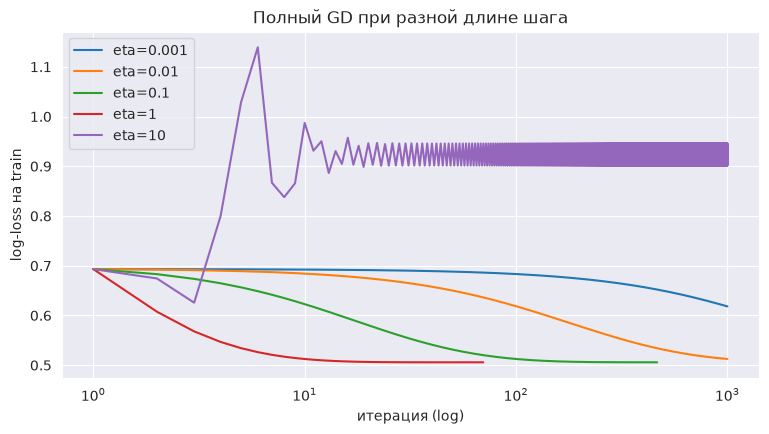

,итераций,останов,финальный loss,min loss
eta,,,,
0.001,1000,max_iter,0.618141,0.618141
0.010,1000,max_iter,0.512451,0.512451
0.100,465,tolerance,0.505762,0.505762
1.000,70,tolerance,0.505757,0.505757
10.000,1000,max_iter,0.945807,0.625651


In [7]:
etas = [1e-3, 1e-2, 1e-1, 1, 10]
eta_models = {}
rows = []
plt.figure(figsize=(9, 4.5))
for eta in etas:
    m = LogReg(gd_type='full', eta=eta).fit(X_train, y_train)
    eta_models[eta] = m
    rows.append({'eta': eta, 'итераций': m.n_iter_, 'останов': m.stop_reason_,
                 'финальный loss': m.loss_history[-1], 'min loss': min(m.loss_history)})
    plt.plot(np.arange(1, len(m.loss_history) + 1), m.loss_history, label=f'eta={eta:g}')
plt.xscale('log')
plt.xlabel('итерация (log)')
plt.ylabel('log-loss на train')
plt.title('Полный GD при разной длине шага')
plt.legend()
plt.show()

pd.DataFrame(rows).set_index('eta')

**Выводы 1.3.**
- `eta` 0.001 и 0.01: сходимость медленная, за 1000 итераций минимум не достигнут.
- `eta` 0.1 и 1: сходятся к минимуму 0.5058 за 465 и 70 итераций, останов по `tolerance`.
- `eta=10`: шаг слишком большой, loss скачет и в конце (0.946) выше начального (0.693). Спуск не сходится.

Маленький шаг дает медленную сходимость, слишком большой дает расходимость.

### Задание 1.4. Сравнение с `sklearn` (0.5 балла)

1. Обучите `LogisticRegression` из `sklearn` с параметрами по умолчанию.
2. Для трёх моделей (ваш GD, ваш SGD, `sklearn`) посчитайте на тестовой выборке accuracy и ROC-AUC и сведите их в таблицу `pd.DataFrame`.
3. Сравните веса вашей модели (GD) с весами модели `sklearn` (`intercept_` и `coef_`).

Ответьте на вопросы:
   - Совпадают ли метрики? Совпадают ли веса?
   - Что в модели `sklearn` по умолчанию делает её не равной вашей? Найдите ответ в [документации](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html). Как настроить `LogisticRegression`, чтобы она решала ту же задачу оптимизации, что и ваша модель?

In [8]:
sk = LogisticRegression().fit(X_train, y_train)

def acc_auc(model):
    p = model.predict_proba(X_test)[:, 1]
    return {'accuracy': metrics.accuracy_score(y_test, model.predict(X_test)),
            'ROC-AUC': metrics.roc_auc_score(y_test, p)}

res_1_4 = pd.DataFrame({'LogReg GD': acc_auc(gd),
                        'LogReg SGD': acc_auc(sgd),
                        'sklearn LogisticRegression': acc_auc(sk)}).T
display(res_1_4)

weights = pd.DataFrame({'LogReg GD': gd.w,
                        'sklearn (C=1, L2)': np.r_[sk.intercept_, sk.coef_.ravel()]},
                       index=['w0 (intercept)'] + [f'x{j}' for j in range(1, X_train.shape[1] + 1)])
weights['|разность|'] = (weights.iloc[:, 0] - weights.iloc[:, 1]).abs()
display(weights.round(4))

,accuracy,ROC-AUC
LogReg GD,0.7820,0.838787
LogReg SGD,0.7825,0.838115
sklearn LogisticRegression,0.7765,0.838676


,LogReg GD,"sklearn (C=1, L2)",|разность|
w0 (intercept),-0.0021,-0.0219,0.0198
x1,0.0061,0.0027,0.0033
x2,0.0070,0.0090,0.0021
x3,-0.5472,-0.7227,0.1755
x4,-0.1445,-0.2623,0.1178
x5,0.0125,0.0166,0.0041
x6,-0.0063,-0.0115,0.0052
x7,0.0008,0.0056,0.0048
x8,0.0391,0.0572,0.0181
x9,-0.0024,-0.0012,0.0012


In [9]:
# sklearn без регуляризации и GD, доведенный до сходимости
sk_noreg = LogisticRegression(C=np.inf, tol=1e-10, max_iter=10_000).fit(X_train, y_train)
gd_conv = LogReg(gd_type='full', eta=1, max_iter=100_000, tolerance=1e-8).fit(X_train, y_train)
print('GD до сходимости: итераций =', gd_conv.n_iter_, ', останов по', gd_conv.stop_reason_)

w_sk_noreg = np.r_[sk_noreg.intercept_, sk_noreg.coef_.ravel()]
print('max |w_GD - w_sklearn(C=inf)| =', np.abs(gd_conv.w - w_sk_noreg).max())

GD до сходимости: итераций = 167 , останов по tolerance
max |w_GD - w_sklearn(C=inf)| = 5.4141542249475094e-08


**Выводы 1.4.**
- Метрики почти совпадают (ROC-AUC 0.8388, 0.8381, 0.8387), разница в третьем знаке.
- Веса не совпадают: знаки и важные признаки те же, но у sklearn веса больше по модулю. Причины: у sklearn по умолчанию L2-регуляризация с `C=1.0`, а наш GD с `eta=0.01` за 1000 итераций не дошел до минимума.
- Чтобы sklearn решал ту же задачу, нужно отключить регуляризацию: `LogisticRegression(C=np.inf)` (в старых версиях `penalty=None`). В ячейке выше при этом и сошедшемся GD веса совпадают до 5e-8.

## <font color="green">Часть 2. Метрики классификации (2.5 балла)</font>

### Данные

Используем датасет [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) (P. Cortez et al., 2009, лицензия CC BY 4.0).
Каждая строка – образец португальского вина: 11 физико-химических характеристик и признак `is_red` (1 - красное, 0 - белое). Эксперты оценили каждое вино по шкале от 0 до 10. Мы превратили оценку в бинарную целевую переменную:

- `target = 1` – «хорошее» вино (оценка не ниже 7);
- `target = 0` – все остальные.

**Сценарий.** Сервис по подписке каждый месяц рекомендует клиентам вина. Модель должна по результатам лабораторного анализа отбирать «хорошие» вина в подборку. Рекомендовать клиенту посредственное вино — плохо (клиент разочаруется), но и пропускать хорошие вина тоже не хочется (подборка получится скудной).

In [10]:
df = pd.read_csv('https://raw.githubusercontent.com/paiflare/ml_hse_2026/refs/heads/master/homework/hw_3/Data/wine_quality.csv')

print('Data shape:', df.shape)
df.head()

Data shape: (6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,is_red,target
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,1,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,1,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,1,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0


In [11]:
X = df.drop(columns='target')
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (4547, 12)  Test: (1950, 12)


### Задание 2.1. Первичный анализ и accuracy (0.25 балла)

1. Проверьте данные на пропуски и полные дубликаты строк. Нужно ли удалять дубликаты в этой задаче? Посчитайте долю класса 1 (prevalence) в тренировочной и тестовой выборках. Зачем при разбиении был указан параметр `stratify=y`?
2. Посчитайте accuracy на тестовой выборке для константной модели, которая всегда отвечает «не хорошее вино» (класс 0).
3. Обучите пайплайн `make_pipeline(StandardScaler(), LogisticRegression())` и посчитайте его accuracy на тестовой выборке.

Сравните два числа. Почему accuracy плохо подходит для этой задачи?

In [12]:
# 1. Пропуски, дубликаты, prevalence
print('Пропусков всего:', df.isna().sum().sum())
n_dup = df.duplicated().sum()
print(f'Полных дубликатов строк: {n_dup} ({n_dup / len(df):.1%})')
print(f'Prevalence train: {y_train.mean():.4f}, test: {y_test.mean():.4f}, весь датасет: {y.mean():.4f}')

train_keys = set(map(tuple, X_train.values))
in_train = np.mean([tuple(r) in train_keys for r in X_test.values])
print(f'Доля объектов test, совпадающих с каким-то объектом train: {in_train:.1%}')

# 2. Константная модель
acc_const = metrics.accuracy_score(y_test, np.zeros_like(y_test))
# 3. Логистическая регрессия
pipe = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_train, y_train)
acc_lr = metrics.accuracy_score(y_test, pipe.predict(X_test))
print(f'\nAccuracy константы "всегда 0": {acc_const:.4f}')
print(f'Accuracy логистической регрессии: {acc_lr:.4f}')

Пропусков всего: 0
Полных дубликатов строк: 1177 (18.1%)
Prevalence train: 0.1966, test: 0.1964, весь датасет: 0.1966
Доля объектов test, совпадающих с каким-то объектом train: 27.5%

Accuracy константы "всегда 0": 0.8036
Accuracy логистической регрессии: 0.8200


**Выводы 2.1.**
- Пропусков нет. Полных дубликатов 1177 (18%). Удалять их не обязательно: это реальные образцы с одинаковыми измерениями. Но 27.5% объектов test есть и в train, поэтому оценка на тесте немного завышена.
- Доля класса 1 около 0.197 в train и в test. `stratify=y` сохраняет эту долю одинаковой в обеих частях, иначе при дисбалансе метрики на train и test были бы несравнимы.
- Accuracy константы "всегда 0" равна 0.804, логистической регрессии 0.820. Модель лучше всего на 1.6 п.п. При дисбалансе accuracy в основном показывает долю класса 0 и не отражает, насколько хорошо находится класс 1.

### Задание 2.2. Матрица ошибок своими руками (0.5 балла)

Для пайплайна логистической регрессии из задания 2.1 получите предсказания классов на тестовой выборке.

1. Посчитайте TP, TN, FP, FN **без функций из `sklearn.metrics`** – только средствами `numpy`/`pandas`.
2. Сравните результат с `metrics.confusion_matrix` и нарисуйте матрицу ошибок с помощью `metrics.ConfusionMatrixDisplay`.
3. Объясните в терминах сценария, что означают FP и FN в этой задаче. Какая из ошибок модели встречается чаще?

TP=98, TN=1501, FP=66, FN=285
sklearn confusion_matrix:
 [[1501   66]
 [ 285   98]]
Совпадает с ручным подсчетом: True


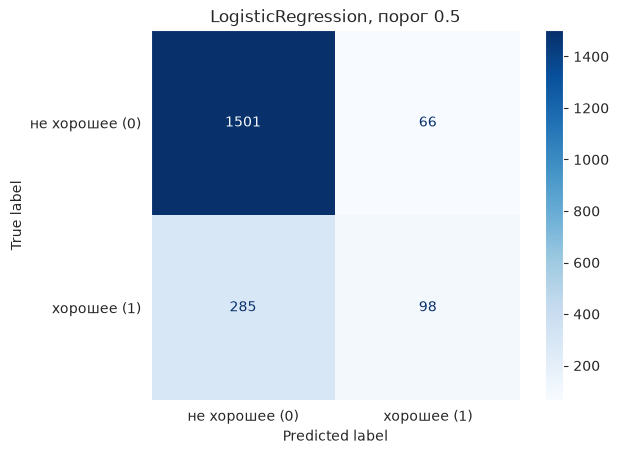

In [13]:
y_pred = pipe.predict(X_test)
yt = np.asarray(y_test)

TP = int(np.sum((y_pred == 1) & (yt == 1)))
TN = int(np.sum((y_pred == 0) & (yt == 0)))
FP = int(np.sum((y_pred == 1) & (yt == 0)))
FN = int(np.sum((y_pred == 0) & (yt == 1)))
print(f'TP={TP}, TN={TN}, FP={FP}, FN={FN}')

my_cm = np.array([[TN, FP], [FN, TP]])
cm = metrics.confusion_matrix(y_test, y_pred)
print('sklearn confusion_matrix:\n', cm)
print('Совпадает с ручным подсчетом:', np.array_equal(my_cm, cm))

metrics.ConfusionMatrixDisplay(cm, display_labels=['не хорошее (0)', 'хорошее (1)']).plot(cmap='Blues')
plt.grid(False)
plt.title('LogisticRegression, порог 0.5')
plt.show()

**Выводы 2.2.** Ручной подсчет совпал с `confusion_matrix`: TN=1501, FP=66, FN=285, TP=98.
- FP: посредственное вино попало в подборку, клиент разочарован.
- FN: хорошее вино пропущено, подборка беднее.

Чаще встречается FN (285 против 66): при пороге 0.5 модель находит только 98 из 383 хороших вин.

### Задание 2.3. Precision, recall, $F_\beta$ (0.5 балла)

1. Используя TP, TN, FP, FN из задания 2.2, посчитайте по формулам precision, recall, $F_1$, $F_{0.5}$ и $F_2$:

$$F_{\beta} = (1 + \beta^2)\frac{\text{Precision} \cdot \text{Recall}}{\beta^2 \cdot \text{Precision} + \text{Recall}}.$$

2. Проверьте свои значения с помощью `metrics.precision_score`, `metrics.recall_score`, `metrics.fbeta_score`.
3. Ответьте на вопросы:
   - Что больше ценится в $F_{0.5}$, а что в $F_2$ – precision или recall?
   - Какую из трёх F-мер вы бы выбрали для нашего сценария, если подписчики очень болезненно реагируют на посредственные вина в подборке? А если сервис позиционирует себя как «самая широкая подборка хороших вин»?

In [14]:
precision = TP / (TP + FP)
recall = TP / (TP + FN)

def f_beta(p, r, beta):
    return (1 + beta**2) * p * r / (beta**2 * p + r)

mine = {'precision': precision, 'recall': recall,
        'F1': f_beta(precision, recall, 1),
        'F0.5': f_beta(precision, recall, 0.5),
        'F2': f_beta(precision, recall, 2)}
skl = {'precision': metrics.precision_score(y_test, y_pred),
       'recall': metrics.recall_score(y_test, y_pred),
       'F1': metrics.fbeta_score(y_test, y_pred, beta=1),
       'F0.5': metrics.fbeta_score(y_test, y_pred, beta=0.5),
       'F2': metrics.fbeta_score(y_test, y_pred, beta=2)}
res_2_3 = pd.DataFrame({'вручную': mine, 'sklearn': skl})
res_2_3['совпадает'] = np.isclose(res_2_3['вручную'], res_2_3['sklearn'])
res_2_3

,вручную,sklearn,совпадает
precision,0.597561,0.597561,True
recall,0.255875,0.255875,True
F1,0.358318,0.358318,True
F0.5,0.471607,0.471607,True
F2,0.288915,0.288915,True


**Выводы 2.3.** Значения совпали с sklearn: precision 0.598, recall 0.256, F1 0.358, F0.5 0.472, F2 0.289.
- В $F_{0.5}$ больше ценится precision, в $F_2$ recall.
- Если клиенты болезненно реагируют на посредственные вина, выбираем $F_{0.5}$. Если важна самая широкая подборка, выбираем $F_2$.

### Задание 2.4. ROC- и PR-кривые (0.5 балла)

Сравним две модели:
- `make_pipeline(StandardScaler(), LogisticRegression())` из `sklearn`;
- ваш `LogReg(gd_type='full')` из части 1 (не забудьте масштабировать признаки, подберите `eta` и `max_iter` так, чтобы спуск сошёлся).

1. Для каждой модели получите на тестовой выборке **непрерывные оценки** (score) – вероятность класса 1.
2. Постройте ROC-кривые двух моделей на одном графике и PR-кривые двух моделей на другом графике. На PR-графике отметьте горизонтальной линией уровень случайной модели.
3. Посчитайте ROC-AUC (`metrics.roc_auc_score`) и PR-AUC (`metrics.average_precision_score`) и сведите в таблицу.
4. Возьмите вероятности $p$ класса 1 модели из `sklearn` и посчитайте ROC-AUC для преобразованных оценок: $10 \cdot p$, $p^3$, $\log\frac{p}{1-p}$, $-p$. Объясните результат.

Ответьте на вопросы:
- Какая модель лучше? Совпадает ли ранжирование моделей по ROC-AUC и по PR-AUC?
- Чему равен PR-AUC случайной модели в этой задаче и почему он не равен 0.5?
- Что получится, если подать в `roc_auc_score` предсказанные метки классов?

Свой LogReg: итераций = 3765 , останов по tolerance


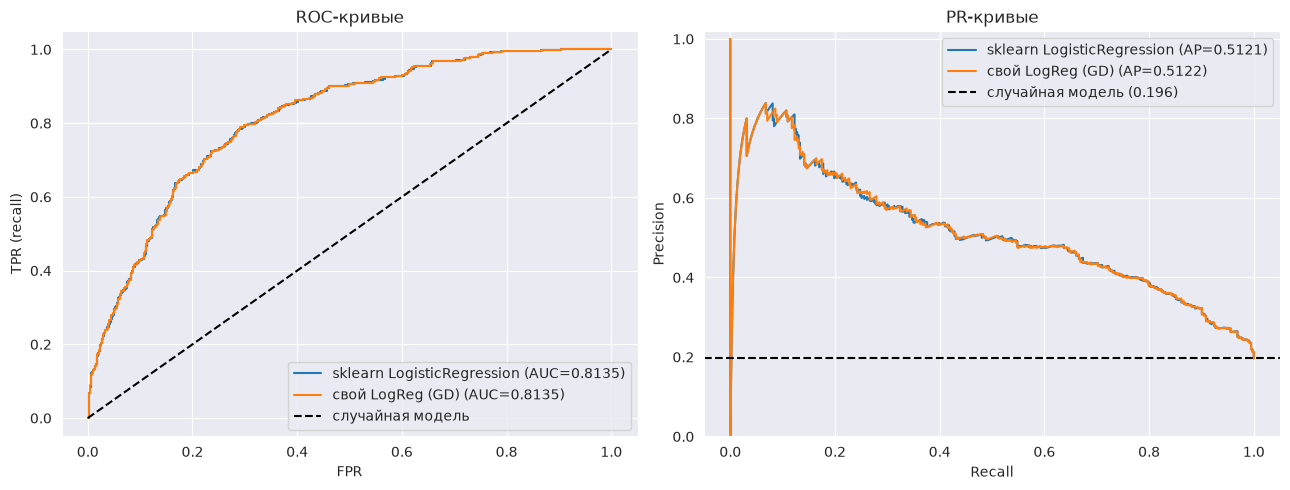

,ROC-AUC,PR-AUC (AP)
sklearn LogisticRegression,0.813537,0.512115
свой LogReg (GD),0.813512,0.512230


,ROC-AUC
p,0.813537
10*p,0.813537
p^3,0.813537
log(p/(1-p)),0.813537
-p,0.186463


ROC-AUC по меткам: 0.6069; (TPR + TNR) / 2 = 0.6069; balanced accuracy = 0.6069


In [15]:
my_pipe = make_pipeline(StandardScaler(), LogReg(gd_type='full', eta=1, max_iter=20_000, tolerance=1e-6))
my_pipe.fit(X_train, y_train)
print('Свой LogReg: итераций =', my_pipe[-1].n_iter_, ', останов по', my_pipe[-1].stop_reason_)

scores = {'sklearn LogisticRegression': pipe.predict_proba(X_test)[:, 1],
          'свой LogReg (GD)': my_pipe.predict_proba(X_test)[:, 1]}
prevalence = y_test.mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, s in scores.items():
    fpr, tpr, _ = metrics.roc_curve(y_test, s)
    axes[0].plot(fpr, tpr, label=f'{name} (AUC={metrics.roc_auc_score(y_test, s):.4f})')
    prec, rec, _ = metrics.precision_recall_curve(y_test, s)
    axes[1].plot(rec, prec, label=f'{name} (AP={metrics.average_precision_score(y_test, s):.4f})')
axes[0].plot([0, 1], [0, 1], 'k--', label='случайная модель')
axes[0].set(xlabel='FPR', ylabel='TPR (recall)', title='ROC-кривые')
axes[1].axhline(prevalence, color='k', ls='--', label=f'случайная модель ({prevalence:.3f})')
axes[1].set(xlabel='Recall', ylabel='Precision', title='PR-кривые', ylim=(0, 1.02))
for ax in axes:
    ax.legend(loc='best')
plt.tight_layout()
plt.show()

display(pd.DataFrame({name: {'ROC-AUC': metrics.roc_auc_score(y_test, s),
                             'PR-AUC (AP)': metrics.average_precision_score(y_test, s)}
                      for name, s in scores.items()}).T)

# Преобразования оценок
p = np.clip(scores['sklearn LogisticRegression'], 1e-15, 1 - 1e-15)
transforms = {'p': p, '10*p': 10 * p, 'p^3': p**3, 'log(p/(1-p))': np.log(p / (1 - p)), '-p': -p}
display(pd.Series({k: metrics.roc_auc_score(y_test, v) for k, v in transforms.items()},
                  name='ROC-AUC').to_frame())

# ROC-AUC по меткам классов
labels = pipe.predict(X_test)
auc_labels = metrics.roc_auc_score(y_test, labels)
tpr_l = metrics.recall_score(y_test, labels)
tnr_l = metrics.recall_score(y_test, labels, pos_label=0)
print(f'ROC-AUC по меткам: {auc_labels:.4f}; (TPR + TNR) / 2 = {(tpr_l + tnr_l) / 2:.4f}; '
      f'balanced accuracy = {metrics.balanced_accuracy_score(y_test, labels):.4f}')

**Выводы 2.4.**
- Модели практически одинаковы: ROC-AUC 0.8135 у обеих, PR-AUC 0.5121 и 0.5122. Формально по ROC-AUC чуть выше sklearn, по PR-AUC свой GD, но разница в 4-5 знаке.
- PR-AUC случайной модели равен доле класса 1, около 0.196. У случайных оценок precision при любом пороге равен доле хороших вин, а 0.5 это значение ROC-AUC случайной модели.
- $10p$, $p^3$ и $\log\frac{p}{1-p}$ не меняют порядок объектов, поэтому ROC-AUC тот же (0.8135): он зависит только от ранжирования. $-p$ переворачивает порядок, ROC-AUC становится 1 - 0.8135 = 0.1865.
- Если подать метки классов, ROC-кривая строится по одной точке, и ROC-AUC равен (TPR + TNR) / 2 = 0.607, то есть balanced accuracy.

### Задание 2.5. Выбор порога (0.75 балла)

Порог 0.5 у логистической регрессии ничем не выделен – его можно и нужно выбирать под задачу. Но подбирать порог на тестовой выборке нельзя: тогда оценка качества на тесте окажется завышенной.

1. Выделите из тренировочной выборки валидационную (`test_size=0.25`, `stratify`, `random_state=42`). Обучите пайплайн логистической регрессии на оставшейся части и получите вероятности на валидации.
2. Постройте на одном графике зависимость precision, recall и $F_1$ на валидации от порога $t \in [0, 1]$.
3. По валидации выберите два порога:
   - $t_{F_1}$ – максимизирующий $F_1$;
   - $t_{R}$ – дающий максимальный precision при условии recall $\ge 0.7$ (сервис хочет, чтобы в подборку попадало не меньше 70% хороших вин).
4. Переобучите пайплайн на всей тренировочной выборке и посчитайте на тестовой выборке precision, recall и $F_1$ при порогах $0.5$, $t_{F_1}$ и $t_{R}$. Сведите результаты в таблицу.

Выполнилось ли на тесте условие recall $\ge 0.7$? Почему порог, подобранный на валидации, не гарантирует выполнения условия на новых данных? Какой порог вы бы выбрали для сценария из описания данных и почему?

t_F1 = 0.268  (валидация: F1 = 0.5455)
t_R  = 0.243  (валидация: precision = 0.4385, recall = 0.7009)


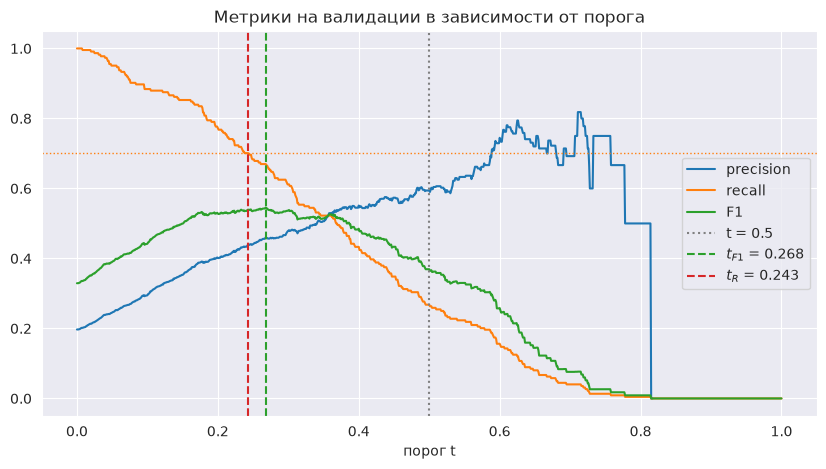

,precision,recall,F1
0.5,0.597561,0.255875,0.358318
t_F1 = 0.268,0.473180,0.644909,0.545856
t_R = 0.243,0.436975,0.678851,0.531697


In [16]:
# 1. Валидация из train
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=RANDOM_STATE)
pipe_val = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_tr, y_tr)
p_val = pipe_val.predict_proba(X_val)[:, 1]

def prf_on_grid(y_true, proba, thresholds):
    y_true = np.asarray(y_true).astype(bool)
    pred = proba[:, None] >= thresholds[None, :]
    tp = (pred & y_true[:, None]).sum(0)
    fp = (pred & ~y_true[:, None]).sum(0)
    fn = (~pred & y_true[:, None]).sum(0)
    with np.errstate(invalid='ignore', divide='ignore'):
        prec = np.where(tp + fp > 0, tp / (tp + fp), np.nan)
        rec = tp / (tp + fn)
        f1 = np.where(tp > 0, 2 * tp / (2 * tp + fp + fn), 0.0)
    return prec, rec, f1

thresholds = np.linspace(0, 1, 1001)
prec_v, rec_v, f1_v = prf_on_grid(y_val, p_val, thresholds)

# 3. Выбор порогов по валидации
t_F1 = thresholds[np.nanargmax(f1_v)]
mask = rec_v >= 0.7
t_R = thresholds[mask][np.nanargmax(prec_v[mask])]
print(f't_F1 = {t_F1:.3f}  (валидация: F1 = {np.nanmax(f1_v):.4f})')
i_R = np.where(thresholds == t_R)[0][0]
print(f't_R  = {t_R:.3f}  (валидация: precision = {prec_v[i_R]:.4f}, recall = {rec_v[i_R]:.4f})')

# 2. График
plt.figure(figsize=(10, 5))
plt.plot(thresholds, prec_v, label='precision')
plt.plot(thresholds, rec_v, label='recall')
plt.plot(thresholds, f1_v, label='F1')
plt.axvline(0.5, color='gray', ls=':', label='t = 0.5')
plt.axvline(t_F1, color='C2', ls='--', label=f'$t_{{F1}}$ = {t_F1:.3f}')
plt.axvline(t_R, color='C3', ls='--', label=f'$t_R$ = {t_R:.3f}')
plt.axhline(0.7, color='C1', ls=':', lw=1)
plt.xlabel('порог t')
plt.title('Метрики на валидации в зависимости от порога')
plt.legend()
plt.show()

# 4. pipe из 2.1 обучен на всем train
p_test = pipe.predict_proba(X_test)[:, 1]
rows = {}
for name, t in [('0.5', 0.5), (f't_F1 = {t_F1:.3f}', t_F1), (f't_R = {t_R:.3f}', t_R)]:
    pr = (p_test >= t).astype(int)
    rows[name] = {'precision': metrics.precision_score(y_test, pr),
                  'recall': metrics.recall_score(y_test, pr),
                  'F1': metrics.f1_score(y_test, pr)}
res_2_5 = pd.DataFrame(rows).T
res_2_5

**Выводы 2.5.**
- На валидации: $t_{F_1}$ = 0.268, $t_R$ = 0.243 (recall 0.701).
- На тесте при $t_R$ recall = 0.679, условие recall >= 0.7 не выполнилось. Порог выбран на небольшой валидации (около 220 хороших вин) почти точно на границе 0.7. На новых данных recall случайно колеблется, а финальная модель обучена на всем train и дает немного другие вероятности.
- Выбираю $t_{F_1}$ = 0.268: на тесте у него лучший F1 (0.546), найдено 65% хороших вин при precision 0.47. Порог 0.5 дает слишком маленькую подборку (recall 0.26).

## <font color="green">Часть 3. Несбалансированные классы (2.5 балла)</font>

Класс «хорошее вино» встречается примерно в 5 раз реже остальных. На семинаре 4 мы обсуждали, что с этим можно сделать:
- задать классам веса (`class_weight='balanced'`);
- сбалансировать обучающую выборку: undersampling, oversampling и их комбинации (библиотека [imbalanced-learn](https://imbalanced-learn.org/stable/)).

Во всех заданиях этой части сравнивайте модели по одному и тому же набору метрик на тестовой выборке: accuracy, precision, recall, $F_1$ (при пороге по умолчанию), ROC-AUC и PR-AUC. Удобно написать для этого одну функцию, которая принимает обученную модель и возвращает строку таблицы.

**Важно:** ресемплинг применяется **только к тренировочной выборке**. Тестовая выборка остаётся нетронутой, иначе метрики перестанут отражать качество на реальном распределении классов.

### Задание 3.1. Веса классов (0.5 балла)

Обучите логистическую регрессию в пайплайне со `StandardScaler` с параметром `class_weight=None` и `class_weight='balanced'`. Сведите метрики двух моделей в таблицу.

1. Какие веса получают объекты классов 0 и 1 при `class_weight='balanced'`? Посчитайте их по формуле из документации `sklearn`.
2. Какие метрики заметно изменились, а какие почти нет? Объясните, почему.

In [17]:
from imblearn.pipeline import make_pipeline as make_imb_pipeline
from imblearn.under_sampling import RandomUnderSampler, NearMiss
from imblearn.over_sampling import RandomOverSampler, SMOTE

def evaluate(model, name, threshold=0.5, X=X_test, y=y_test):
    p = model.predict_proba(X)[:, 1]
    pred = (p >= threshold).astype(int)
    return pd.Series({'accuracy': metrics.accuracy_score(y, pred),
                      'precision': metrics.precision_score(y, pred, zero_division=0),
                      'recall': metrics.recall_score(y, pred),
                      'F1': metrics.f1_score(y, pred),
                      'ROC-AUC': metrics.roc_auc_score(y, p),
                      'PR-AUC': metrics.average_precision_score(y, p)}, name=name)

pipe_bal = make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced')).fit(X_train, y_train)

table = pd.DataFrame([evaluate(pipe, "LR, class_weight=None"),
                      evaluate(pipe_bal, "LR, class_weight='balanced'")])
display(table)

# n_samples / (n_classes * n_c)
counts = np.bincount(y_train)
w_bal = len(y_train) / (2 * counts)
print('Размеры классов в train:', dict(enumerate(counts)))
print(f'Веса: класс 0 -> {w_bal[0]:.4f}, класс 1 -> {w_bal[1]:.4f} (отношение {w_bal[1] / w_bal[0]:.2f})')

,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
"LR, class_weight=None",0.820000,0.597561,0.255875,0.358318,0.813537,0.512115
"LR, class_weight='balanced'",0.726667,0.396978,0.754569,0.520252,0.811339,0.500536


Размеры классов в train: {0: np.int64(3653), 1: np.int64(894)}
Веса: класс 0 -> 0.6224, класс 1 -> 2.5431 (отношение 4.09)


**Выводы 3.1.**
- Формула sklearn: $w_c = \frac{n}{2 \cdot n_c}$. В train 3653 объекта класса 0 и 894 класса 1: $w_0 = 0.622$, $w_1 = 2.543$.
- Сильно изменились метрики, зависящие от порога: recall 0.26 -> 0.75, precision 0.60 -> 0.40, F1 0.36 -> 0.52, accuracy 0.82 -> 0.73. Веса поднимают вероятности класса 1, и при пороге 0.5 отбирается больше вин.
- ROC-AUC и PR-AUC почти не изменились (0.814 -> 0.811, 0.512 -> 0.501): они не зависят от порога, а порядок объектов почти тот же.

### Задание 3.2. Ресемплинг (1 балл)

С помощью `imblearn.pipeline.make_pipeline` соберите пайплайны логистической регрессии с разными способами балансировки:
- `RandomUnderSampler`;
- `NearMiss(version=2)`;
- `RandomOverSampler`;
- `SMOTE`.

Для каждого метода выведите размеры классов в обучающей выборке после ресемплинга и добавьте строку в таблицу метрик из задания 3.1.

Ответьте на вопросы:
- Почему здесь нужен `make_pipeline` именно из `imblearn`, а не из `sklearn`? Что произойдёт с тестовой выборкой при вызове `predict` у такого пайплайна?
- Почему нельзя сначала сбалансировать весь датасет, а уже потом разбить его на train и test?
- Какой из методов оказался лучшим по PR-AUC, а какой – худшим? Как вы думаете, почему?
- Для каких из четырёх методов важен порядок шагов «ресемплинг» и «масштабирование» в пайплайне, а для каких нет? Почему? Проверьте на одном из методов, что изменится, если поменять шаги местами.

In [18]:
from sklearn.base import clone

samplers = {'RandomUnderSampler': RandomUnderSampler(random_state=RANDOM_STATE),
            'NearMiss(version=2)': NearMiss(version=2),
            'RandomOverSampler': RandomOverSampler(random_state=RANDOM_STATE),
            'SMOTE': SMOTE(random_state=RANDOM_STATE)}

resampled_pipes = {}
X_train_scaled = StandardScaler().fit_transform(X_train)
for name, sampler in samplers.items():
    p_ = make_imb_pipeline(StandardScaler(), sampler, LogisticRegression()).fit(X_train, y_train)
    resampled_pipes[name] = p_
    _, y_res = clone(sampler).fit_resample(X_train_scaled, y_train)
    print(f'{name:20s}: размеры классов после ресемплинга {dict(pd.Series(y_res).value_counts().sort_index())}')
    table.loc[name] = evaluate(p_, name)

display(table.round(4))

RandomUnderSampler  : размеры классов после ресемплинга {0: np.int64(894), 1: np.int64(894)}


NearMiss(version=2) : размеры классов после ресемплинга {0: np.int64(894), 1: np.int64(894)}
RandomOverSampler   : размеры классов после ресемплинга {0: np.int64(3653), 1: np.int64(3653)}


SMOTE               : размеры классов после ресемплинга {0: np.int64(3653), 1: np.int64(3653)}


,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
"LR, class_weight=None",0.8200,0.5976,0.2559,0.3583,0.8135,0.5121
"LR, class_weight='balanced'",0.7267,0.3970,0.7546,0.5203,0.8113,0.5005
RandomUnderSampler,0.7297,0.4011,0.7624,0.5257,0.8094,0.5008
NearMiss(version=2),0.5441,0.2819,0.8538,0.4238,0.7399,0.4001
RandomOverSampler,0.7267,0.3973,0.7572,0.5211,0.8115,0.5002
SMOTE,0.7292,0.3992,0.7493,0.5209,0.8125,0.5040


In [19]:
# Порядок шагов: scaler -> sampler и sampler -> scaler
order_rows = []
for name in samplers:
    a = make_imb_pipeline(StandardScaler(), clone(samplers[name]), LogisticRegression()).fit(X_train, y_train)
    b = make_imb_pipeline(clone(samplers[name]), StandardScaler(), LogisticRegression()).fit(X_train, y_train)
    pa, pb = a.predict_proba(X_test)[:, 1], b.predict_proba(X_test)[:, 1]
    order_rows.append({'метод': name,
                       'PR-AUC scaler->sampler': metrics.average_precision_score(y_test, pa),
                       'PR-AUC sampler->scaler': metrics.average_precision_score(y_test, pb),
                       'max |Δ proba|': np.abs(pa - pb).max()})
pd.DataFrame(order_rows).set_index('метод')

,PR-AUC scaler->sampler,PR-AUC sampler->scaler,max |Δ proba|
метод,,,
RandomUnderSampler,0.500791,0.500528,0.002678
NearMiss(version=2),0.400108,0.393364,0.875656
RandomOverSampler,0.500225,0.500264,0.001965
SMOTE,0.503985,0.508955,0.127411


**Выводы 3.2.**
- Пайплайн из imblearn вызывает ресемплинг только в `fit`. При `predict` сэмплер пропускается, и тест проходит только через scaler и модель. Пайплайн sklearn шаги с `fit_resample` не поддерживает.
- Если сначала сбалансировать весь датасет, тест перестанет отражать реальное распределение классов, а копии или синтетические объекты из train попадут в test (утечка).
- Лучший по PR-AUC SMOTE (0.504), он не теряет данных. RandomUnder, RandomOver и balanced дают около 0.500. Худший NearMiss-2 (0.400): он оставляет только объекты класса 0, близкие к классу 1, и выборка становится нерепрезентативной.
- Порядок важен для NearMiss и SMOTE, так как они считают расстояния, а без масштабирования расстояния определяются признаками с большим масштабом. Для RandomUnder и RandomOver порядок почти не важен: объекты выбираются случайно, без учета признаков. Проверка в ячейке выше: у NearMiss вероятности меняются до 0.88, у RandomUnder и RandomOver не больше 0.003.

### Задание 3.3. Веса классов или порог? (0.75 балла)

Сравните на тестовой выборке две модели:
- логистическую регрессию с `class_weight='balanced'` и порогом 0.5;
- логистическую регрессию без весов с порогом $t_{F_1}$ из задания 2.5.

Постройте их PR-кривые на одном графике и отметьте на каждой кривой точку, соответствующую выбранному порогу. Сильно ли различаются кривые? Можно ли сказать, что взвешивание классов в основном «сдвигает порог»?

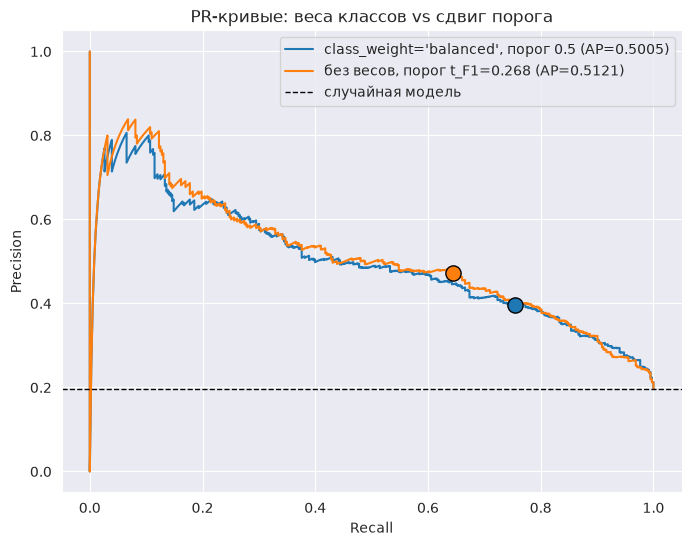

,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
"balanced, t=0.5",0.726667,0.396978,0.754569,0.520252,0.811339,0.500536
"без весов, t_F1=0.268",0.789231,0.473180,0.644909,0.545856,0.813537,0.512115


balanced при 0.5 отбирает 728 вин; модели без весов для того же числа нужен порог ~ 0.199


In [20]:
p_bal = pipe_bal.predict_proba(X_test)[:, 1]
p_none = pipe.predict_proba(X_test)[:, 1]

plt.figure(figsize=(8, 6))
for name, s, t, c in [("class_weight='balanced', порог 0.5", p_bal, 0.5, 'C0'),
                      (f'без весов, порог t_F1={t_F1:.3f}', p_none, t_F1, 'C1')]:
    prec, rec, _ = metrics.precision_recall_curve(y_test, s)
    plt.plot(rec, prec, color=c, label=f'{name} (AP={metrics.average_precision_score(y_test, s):.4f})')
    pr = (s >= t).astype(int)
    plt.scatter(metrics.recall_score(y_test, pr), metrics.precision_score(y_test, pr),
                color=c, s=120, edgecolor='k', zorder=5)
plt.axhline(y_test.mean(), color='k', ls='--', lw=1, label='случайная модель')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('PR-кривые: веса классов vs сдвиг порога')
plt.legend()
plt.show()

display(pd.DataFrame([evaluate(pipe_bal, "balanced, t=0.5"),
                      evaluate(pipe, f"без весов, t_F1={t_F1:.3f}", threshold=t_F1)]))

# Порог модели без весов, при котором отбирается столько же вин, сколько у balanced при 0.5
n_pos = (p_bal >= 0.5).sum()
print(f'balanced при 0.5 отбирает {n_pos} вин; модели без весов для того же числа нужен порог ~ '
      f'{np.sort(p_none)[::-1][n_pos - 1]:.3f}')

**Выводы 3.3.** PR-кривые почти совпадают (AP 0.501 и 0.512). Различаются точки: balanced при 0.5 дает recall 0.75 и precision 0.40, модель без весов при $t_{F_1}$ дает recall 0.64 и precision 0.47. Значит, веса классов в основном сдвигают порог: модель без весов отбирает столько же вин, сколько balanced при 0.5, если взять порог около 0.20.

### Задание 3.4. Итоги (0.25 балла)

Сведите в одну таблицу все модели частей 2 и 3 (метрики на тестовой выборке). Какую модель и какой порог вы бы предложили сервису из сценария? Обоснуйте выбор, опираясь на метрики.

In [21]:
final = pd.DataFrame([
    evaluate(pipe, 'LR (sklearn), t=0.5'),
    evaluate(my_pipe, 'свой LogReg GD, t=0.5'),
    evaluate(pipe, f'LR, t_F1={t_F1:.3f}', threshold=t_F1),
    evaluate(pipe, f'LR, t_R={t_R:.3f}', threshold=t_R),
    evaluate(pipe_bal, "LR balanced, t=0.5"),
    *[evaluate(m, f'{name}, t=0.5') for name, m in resampled_pipes.items()],
])
final.round(4)

,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
"LR (sklearn), t=0.5",0.8200,0.5976,0.2559,0.3583,0.8135,0.5121
"свой LogReg GD, t=0.5",0.8215,0.6036,0.2663,0.3696,0.8135,0.5122
"LR, t_F1=0.268",0.7892,0.4732,0.6449,0.5459,0.8135,0.5121
"LR, t_R=0.243",0.7651,0.4370,0.6789,0.5317,0.8135,0.5121
"LR balanced, t=0.5",0.7267,0.3970,0.7546,0.5203,0.8113,0.5005
"RandomUnderSampler, t=0.5",0.7297,0.4011,0.7624,0.5257,0.8094,0.5008
"NearMiss(version=2), t=0.5",0.5441,0.2819,0.8538,0.4238,0.7399,0.4001
"RandomOverSampler, t=0.5",0.7267,0.3973,0.7572,0.5211,0.8115,0.5002
"SMOTE, t=0.5",0.7292,0.3992,0.7493,0.5209,0.8125,0.5040


**Выводы 3.4.** ROC-AUC и PR-AUC у всех моделей, кроме NearMiss, почти одинаковы, разница в выборе порога. Предлагаю логистическую регрессию без весов с порогом $t_{F_1}$ = 0.268: лучший F1 на тесте (0.546), лучший PR-AUC (0.512), recall 0.645 при precision 0.473. Модели с балансировкой дают больший recall, но меньшие precision и F1.

### Сохранение модели (0 баллов, нужно для части 4)

Сохраните итоговую модель (весь пайплайн, а не только `LogisticRegression`), выбранный порог и тестовую выборку – они понадобятся в приложении. Допишите ячейку под свою итоговую модель.

Если работаете в Colab, скачайте папку `wine_app/` на свой компьютер (например, заархивируйте её и воспользуйтесь `google.colab.files.download`): приложение запускается локально.

In [22]:
import json
import joblib
from pathlib import Path

app_dir = Path('wine_app')
app_dir.mkdir(exist_ok=True)

final_model = pipe
final_threshold = t_F1

joblib.dump(final_model, app_dir / 'model.joblib')
(app_dir / 'config.json').write_text(json.dumps({'threshold': float(final_threshold)}))
X_test.assign(target=y_test).to_csv(app_dir / 'test.csv', index=False)
print('Сохранено:', sorted(p.name for p in app_dir.iterdir()), '| порог =', round(float(final_threshold), 3))

Сохранено: ['README.md', 'app.py', 'config.json', 'model.joblib', 'requirements.txt', 'test.csv'] | порог = 0.268


## <font color="green">Часть 4. Демо-приложение на Streamlit (2.5 балла)</font>

Модель в ноутбуке видите только вы. Чтобы ей мог пользоваться сомелье сервиса (и чтобы он понимал, почему меняется подборка при изменении порога), сделаем небольшое веб-приложение.

[Streamlit](https://docs.streamlit.io/) это библиотека, которая которая превращает обычный Python-скрипт в веб-страницу: каждый вызов вроде `st.slider(...)` или `st.write(...)` рисует элемент интерфейса, а при любом действии пользователя скрипт перезапускается сверху вниз. Минимальный пример:

```python
import streamlit as st

t = st.slider('Порог', 0.0, 1.0, 0.5)
st.write('Вы выбрали порог', t)
```

Приложение запускается **локально**, а не в Colab:

```bash
pip install streamlit
streamlit run app.py
```

Полезные элементы: [`st.number_input`](https://docs.streamlit.io/develop/api-reference/widgets/st.number_input), [`st.slider`](https://docs.streamlit.io/develop/api-reference/widgets/st.slider), [`st.tabs`](https://docs.streamlit.io/develop/api-reference/layout/st.tabs), [`st.file_uploader`](https://docs.streamlit.io/develop/api-reference/widgets/st.file_uploader), [`st.download_button`](https://docs.streamlit.io/develop/api-reference/widgets/st.download_button), [`st.pyplot`](https://docs.streamlit.io/develop/api-reference/charts/st.pyplot), [`st.metric`](https://docs.streamlit.io/develop/api-reference/data/st.metric), [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource) (чтобы не загружать модель заново при каждом перезапуске скрипта).

Приложение `wine_app/app.py` использует файлы, сохранённые в ячейке выше (`model.joblib`, `config.json`, `test.csv`). **Модель внутри приложения не обучается.**

### Задание 4.1. Оценка одного вина (0.5 балла)

Сделайте вкладку, на которой пользователь вводит 12 признаков вина (диапазоны и значения по умолчанию возьмите из данных, например минимум, максимум и медиану по `test.csv`; признак `is_red` – переключатель «красное / белое»). Сделайте сайдбар с интерактивным ползунком значения порога, установите порог по умолчанию значением из файла `config.json`. Приложение показывает вероятность того, что вино хорошее, и решение модели при установленном пороге.

### Задание 4.2. Интерактивная визуализация модельных метрик (0.5 балла)

Сделайте вкладку «Модельные метрики». При изменении порога на тестовой выборке пересчитываются и выводятся:
- матрица ошибок;
- precision, recall и $F_1$;
- ROC- и PR-кривые, на которых отмечена точка, соответствующая текущему порогу.

Добавьте короткий текст для сомелье: что произойдёт с подборкой, если порог увеличить или уменьшить.

### Задание 4.3. Пакетное предсказание (0.5 балла)

Сделайте вкладку, на которой пользователь загружает CSV-файл с признаками вин (без столбца `target`), а приложение показывает таблицу с вероятностью и решением для каждого вина и даёт скачать её через `st.download_button`. Порог для этой вкладки берётся из слайдера задания 4.2 (подсказка: [`st.session_state`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.session_state)) или задаётся отдельно – на ваш выбор.

Приложение не должно падать, если в файле не хватает столбцов: в этом случае выведите понятное сообщение об ошибке (`st.error`).

### Задание 4.4. Что выучила модель (0.25 балла)

Сделайте вкладку с горизонтальной столбчатой диаграммой коэффициентов логистической регрессии (после масштабирования признаков), отсортированных по значению. Подпишите, какие признаки сильнее всего «голосуют» за хорошее вино, а какие – против.

### Задание 4.5. Кэширование (0.25 балла)

Streamlit выполняет `app.py` заново при каждом действии пользователя: сдвинули слайдер порога – скрипт отработал сверху вниз ещё раз. Без кэширования при каждом движении слайдера модель снова читается с диска, а вероятности на тестовой выборке пересчитываются, хотя от порога они не зависят.

1. Модель загружается функцией с декоратором [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource): один объект на весь сервер. Путь к файлу строится от папки, где лежит `app.py` (`Path(__file__).parent`), а не от текущей директории.
2. `test.csv` читается функцией с декоратором [`st.cache_data`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_data).
3. Вероятности класса 1 на тестовой выборке считаются один раз, в функции с `st.cache_data`. При движении слайдера в задании 4.2 меняется только сравнение с порогом, `predict_proba` заново не вызывается. Подсказка: аргумент, который Streamlit не должен хешировать (например, модель), называют с подчёркиванием в начале: `def test_proba(_model, X): ...`.

Ответьте в `README.md` или в комментарии в `app.py`: почему для модели используется `st.cache_resource`, а для таблиц – `st.cache_data`? Что изменится, если вызвать `joblib.load` без декоратора?

Использование `joblib.load` без декоратора или загрузка модели через `st.cache_data` за этот пункт не засчитываются.

### Задание 4.6. Оформление и сдача (0.5 балла)

1. Сдайте папку `wine_app/` (архивом или укажите в клетке ниже ссылку на Github репозиторий) со следующим содержимым:
- `app.py`;
- `model.joblib`, `config.json`, `test.csv`;
- `requirements.txt` с версиями библиотек, при которых приложение запускается;
- `README.md`: инструкция о том, как запустить приложение с указанием версии Python интерпретатора.

2. Проведите деплой приложения на [Streamlit Community Cloud](https://streamlit.io/cloud).

Приложение лежит в папке `wine_app/`. Ответ на вопрос 4.5 есть в `wine_app/README.md`.

Репозиторий: https://github.com/Chasik8/HSE/tree/master/mmad/3

Ссылка на деплой: https://chasik8-hse-mmad3wine-appapp-9arkve.streamlit.app/

**Опишите общие мысли о работе. Это место для вашей рефлексии – необязательное, но полезное.** 🍷